In [1]:
import pickle
from pathlib import Path

out_dir = Path("/Users/javier/FLAMES_30dor/gausspyp_v02.2/gausspy_validation")

FILENAME_DATA = out_dir / "real_FLAMES_validation_input.pkl"
FILENAME_DATA_DECOMP = out_dir / "real_FLAMES_validation_decomposed.pkl"
FILENAME_DF_VALIDATION = out_dir / "df_validation.pkl"
FILENAME_CONFIG = out_dir / "validation_training_config.pkl"

with open(FILENAME_DATA, "rb") as f:
    gauss_input = pickle.load(f)

with open(FILENAME_DATA_DECOMP, "rb") as f:
    data_decomp = pickle.load(f)

with open(FILENAME_DF_VALIDATION, "rb") as f:
    df_validation = pickle.load(f)

with open(FILENAME_CONFIG, "rb") as f:
    training_config = pickle.load(f)

print("gauss_input:", type(gauss_input))
print("data_decomp:", type(data_decomp))
print("df_validation:", type(df_validation))
print("training_config:", training_config)

gauss_input: <class 'dict'>
data_decomp: <class 'dict'>
df_validation: <class 'pandas.core.frame.DataFrame'>
training_config: {'phase': 'two', 'alpha1': 0.9, 'alpha2': 1.72, 'SNR_thresh': [10, 10], 'input_file': '/Users/javier/FLAMES_30Dor/gausspyp_v02.2/gausspy_validation/real_FLAMES_validation_input.pkl', 'decomposition_file': '/Users/javier/FLAMES_30Dor/gausspyp_v02.2/gausspy_validation/real_FLAMES_validation_decomposed.pkl', 'notes': 'FLAMES 30 Dor validation sample using trained GaussPy two-phase parameters.'}


In [2]:
import numpy as np
import pandas as pd


def make_validation_summary(
    gauss_input,
    data_decomp,
    lambda0_nm=656.28,
    rchi2_threshold=20,
    many_components_threshold=5,
):
    """
    Build a compact validation summary table for GaussPy decompositions.

    One row corresponds to one analyzed spectrum.

    Parameters
    ----------
    gauss_input : dict
        Input dictionary used for GaussPy decomposition. Must contain:
        'data_list', 'x_values', 'errors', and 'metadata'.

    data_decomp : dict
        Output dictionary returned by GaussPy batch_decomposition.

    lambda0_nm : float, default=656.28
        Rest wavelength used to convert fitted centers into velocity.
        For Halpha, lambda0_nm ≈ 656.28 nm.

    rchi2_threshold : float, default=20
        Threshold above which the fit is flagged as large chi-square.

    many_components_threshold : int, default=5
        Threshold above which the fit is flagged as having many components.

    Returns
    -------
    summary : pandas.DataFrame
        Validation summary table.
    """

    c_kms = 299792.458

    rows = []

    n_spectra = len(gauss_input["data_list"])

    for i in range(n_spectra):

        metadata = gauss_input["metadata"][i]

        wave = np.asarray(metadata["wave"], dtype=float)

        if len(wave) > 1:
            dw = np.nanmedian(np.diff(wave))
        else:
            dw = np.nan

        wave0 = wave[0] if len(wave) > 0 else np.nan
        wave_min = np.nanmin(wave) if len(wave) > 0 else np.nan
        wave_max = np.nanmax(wave) if len(wave) > 0 else np.nan

        means_fit_chan = np.asarray(data_decomp["means_fit"][i], dtype=float)
        fwhms_fit_chan = np.asarray(data_decomp["fwhms_fit"][i], dtype=float)
        amps_fit = np.asarray(data_decomp["amplitudes_fit"][i], dtype=float)

        means_initial = np.asarray(data_decomp["means_initial"][i], dtype=float)
        fwhms_initial = np.asarray(data_decomp["fwhms_initial"][i], dtype=float)
        amps_initial = np.asarray(data_decomp["amplitudes_initial"][i], dtype=float)

        means_fit_err_chan = np.asarray(data_decomp["means_fit_err"][i], dtype=float)
        fwhms_fit_err_chan = np.asarray(data_decomp["fwhms_fit_err"][i], dtype=float)
        amps_fit_err = np.asarray(data_decomp["amplitudes_fit_err"][i], dtype=float)

        ncomp_initial = len(means_initial)
        ncomp_fit = len(means_fit_chan)

        rchi2 = to_scalar(data_decomp["best_fit_rchi2"][i])

        # Convert channel quantities to wavelength quantities.
        means_fit_nm = wave0 + means_fit_chan * dw
        fwhms_fit_nm = fwhms_fit_chan * dw

        # Convert wavelength quantities to velocity quantities.
        means_fit_kms = c_kms * (means_fit_nm - lambda0_nm) / lambda0_nm
        fwhms_fit_kms = c_kms * fwhms_fit_nm / lambda0_nm

        # Compute sigma
        sigma_obs_kms = fwhms_fit_kms / 2.335
        sigma_kms = (sigma_obs_kms**2-7.8**2-9.1**2)**0.5

        # Basic automatic flags.
        flag_zero_components = ncomp_fit == 0
        flag_many_components = ncomp_fit > many_components_threshold
        flag_large_rchi2 = np.isfinite(rchi2) and rchi2 > rchi2_threshold

        if ncomp_fit > 0:
            flag_center_outside_window = np.any(
                (means_fit_nm < wave_min) | (means_fit_nm > wave_max)
            )
            flag_nonpositive_fwhm = np.any(fwhms_fit_chan <= 0)
        else:
            flag_center_outside_window = False
            flag_nonpositive_fwhm = False

        # Simple automatic quality label.
        if flag_zero_components:
            auto_quality = "zero_components"
        elif flag_nonpositive_fwhm:
            auto_quality = "nonpositive_fwhm"
        elif flag_center_outside_window:
            auto_quality = "center_outside_window"
        elif flag_large_rchi2:
            auto_quality = "large_rchi2"
        elif flag_many_components:
            auto_quality = "many_components"
        else:
            auto_quality = "ok_candidate"

        row = {
            # Identification
            "validation_index": metadata.get("validation_index", i),
            "filename": metadata.get("filename", None),
            "object": metadata.get("object", None),
            "ra_deg": metadata.get("ra_deg", None),
            "dec_deg": metadata.get("dec_deg", None),
            "sample": metadata.get("sample", None),

            # Wavelength window
            "wave_min_nm": wave_min,
            "wave_max_nm": wave_max,
            "dw_nm": dw,

            # Component counts
            "ncomp_initial": ncomp_initial,
            "ncomp_fit": ncomp_fit,

            # Fit quality
            "best_fit_rchi2": rchi2,

            # Raw GaussPy outputs in channel units
            "means_initial_chan": means_initial,
            "fwhms_initial_chan": fwhms_initial,
            "amps_initial": amps_initial,

            "means_fit_chan": means_fit_chan,
            "fwhms_fit_chan": fwhms_fit_chan,
            "amps_fit": amps_fit,

            "means_fit_err_chan": means_fit_err_chan,
            "fwhms_fit_err_chan": fwhms_fit_err_chan,
            "amps_fit_err": amps_fit_err,

            # Converted quantities
            "means_fit_nm": means_fit_nm,
            "fwhms_fit_nm": fwhms_fit_nm,
            "means_fit_kms": means_fit_kms,
            "fwhms_fit_kms": fwhms_fit_kms,

            # Dispersion
            "sigma_obs_kms": sigma_obs_kms,
            "sigma_kms": sigma_kms,


            # Automatic flags
            "flag_zero_components": flag_zero_components,
            "flag_many_components": flag_many_components,
            "flag_large_rchi2": flag_large_rchi2,
            "flag_center_outside_window": flag_center_outside_window,
            "flag_nonpositive_fwhm": flag_nonpositive_fwhm,
            "auto_quality": auto_quality,

            # Manual validation fields
            "visual_quality": "",
            "notes": "",
        }

        rows.append(row)

    summary = pd.DataFrame(rows)

    return summary


In [3]:
def to_scalar(value, default=np.nan):
    """
    Convert GaussPy scalar-like outputs to a float.

    Handles cases like:
    - 1.23
    - [1.23]
    - np.array([1.23])
    - None
    """
    if value is None:
        return default

    arr = np.asarray(value)

    if arr.size == 0:
        return default

    return float(arr.ravel()[0])

In [4]:
df_validation_summary = make_validation_summary(
    gauss_input,
    data_decomp,
    lambda0_nm=656.28,
    rchi2_threshold=20,
    many_components_threshold=5,
)

display(df_validation_summary.head())

/var/folders/1s/7p4dmrfd0d7d8t0h6trn9dhw0000gr/T/ipykernel_84005/2777805695.py:90: RuntimeWarning: invalid value encountered in sqrt
  sigma_kms = (sigma_obs_kms**2-7.8**2-9.1**2)**0.5


,validation_index,filename,object,ra_deg,dec_deg,sample,wave_min_nm,wave_max_nm,dw_nm,ncomp_initial,...,sigma_obs_kms,sigma_kms,flag_zero_components,flag_many_components,flag_large_rchi2,flag_center_outside_window,flag_nonpositive_fwhm,auto_quality,visual_quality,notes
0,0,ADP.2019-01-31T23_53_42.052.fits,pos078,84.550875,-69.148917,None,656.001648,657.496643,0.005005,6,...,"[46.132804974902314, 12.694610454666062, 11.28...","[44.54868903629344, 4.183674771742768, nan, 7....",False,False,False,False,False,ok_candidate,,
1,1,ADP.2019-01-31T23_53_42.083.fits,pos011,84.634750,-69.088028,None,656.001709,657.496704,0.005005,6,...,"[2.209438821991476, 15.62967924246358, 18.9184...","[nan, 10.031793120987738, 14.637540123665676, ...",False,False,True,False,False,large_rchi2,,
2,2,ADP.2019-01-31T23_53_42.122.fits,pos069,84.852375,-69.082583,None,656.001831,657.496826,0.005005,6,...,"[13.350446908930873, 24.062694515314508, 3.443...","[5.880853056163019, 20.865360465070975, nan, 1...",False,False,True,False,False,large_rchi2,,
3,3,ADP.2019-01-31T23_53_42.163.fits,pos037,84.610125,-69.163389,None,656.001709,657.496704,0.005005,9,...,"[17.558453505959637, 13.369413842371802, 23.38...","[12.83157392999574, 5.923784811132387, 20.0756...",False,False,True,False,False,large_rchi2,,
4,4,ADP.2019-01-31T23_53_42.236.fits,pos093,84.460167,-69.170167,None,656.001648,657.496643,0.005005,6,...,"[19.012705222527906, 27.187089582204976, 54.34...","[14.759165283942718, 24.40261953051021, 53.005...",False,False,True,False,False,large_rchi2,,


In [5]:
df_validation_summary.columns

Index(['validation_index', 'filename', 'object', 'ra_deg', 'dec_deg', 'sample',
       'wave_min_nm', 'wave_max_nm', 'dw_nm', 'ncomp_initial', 'ncomp_fit',
       'best_fit_rchi2', 'means_initial_chan', 'fwhms_initial_chan',
       'amps_initial', 'means_fit_chan', 'fwhms_fit_chan', 'amps_fit',
       'means_fit_err_chan', 'fwhms_fit_err_chan', 'amps_fit_err',
       'means_fit_nm', 'fwhms_fit_nm', 'means_fit_kms', 'fwhms_fit_kms',
       'sigma_obs_kms', 'sigma_kms', 'flag_zero_components',
       'flag_many_components', 'flag_large_rchi2',
       'flag_center_outside_window', 'flag_nonpositive_fwhm', 'auto_quality',
       'visual_quality', 'notes'],
      dtype='object')

In [6]:
from astropy.coordinates import SkyCoord
import astropy.units as u

coords = SkyCoord(
    ra=df_validation_summary["ra_deg"].values * u.deg,
    dec=df_validation_summary["dec_deg"].values * u.deg,
    frame="icrs"
)

df_validation_summary["RA_hms"] = coords.ra.to_string(
    unit=u.hour,
    sep=":",
    precision=3,
    pad=True
)

df_validation_summary["Dec_dms"] = coords.dec.to_string(
    unit=u.deg,
    sep=":",
    precision=3,
    alwayssign=True,
    pad=True
)

In [7]:
df_validation_summary

,validation_index,filename,object,ra_deg,dec_deg,sample,wave_min_nm,wave_max_nm,dw_nm,ncomp_initial,...,flag_zero_components,flag_many_components,flag_large_rchi2,flag_center_outside_window,flag_nonpositive_fwhm,auto_quality,visual_quality,notes,RA_hms,Dec_dms
0,0,ADP.2019-01-31T23_53_42.052.fits,pos078,84.550875,-69.148917,None,656.001648,657.496643,0.005005,6,...,False,False,False,False,False,ok_candidate,,,05:38:12.210,-69:08:56.100
1,1,ADP.2019-01-31T23_53_42.083.fits,pos011,84.634750,-69.088028,None,656.001709,657.496704,0.005005,6,...,False,False,True,False,False,large_rchi2,,,05:38:32.340,-69:05:16.900
2,2,ADP.2019-01-31T23_53_42.122.fits,pos069,84.852375,-69.082583,None,656.001831,657.496826,0.005005,6,...,False,False,True,False,False,large_rchi2,,,05:39:24.570,-69:04:57.300
3,3,ADP.2019-01-31T23_53_42.163.fits,pos037,84.610125,-69.163389,None,656.001709,657.496704,0.005005,9,...,False,False,True,False,False,large_rchi2,,,05:38:26.430,-69:09:48.200
4,4,ADP.2019-01-31T23_53_42.236.fits,pos093,84.460167,-69.170167,None,656.001648,657.496643,0.005005,6,...,False,False,True,False,False,large_rchi2,,,05:37:50.440,-69:10:12.600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1377,1377,ADP.2019-01-31T23_53_46.806.fits,t45,84.721708,-69.122194,None,656.001953,657.496948,0.005005,7,...,False,False,False,False,False,ok_candidate,,,05:38:53.210,-69:07:19.900
1378,1378,ADP.2019-01-31T23_53_46.840.fits,t48,84.768417,-69.177750,None,656.001953,657.496948,0.005005,5,...,False,False,False,False,False,ok_candidate,,,05:39:04.420,-69:10:39.900
1379,1379,ADP.2019-01-31T23_53_46.930.fits,t56,84.768417,-69.033306,None,656.001953,657.496948,0.005005,4,...,False,False,False,False,False,ok_candidate,,,05:39:04.420,-69:01:59.900
1380,1380,ADP.2019-01-31T23_53_47.091.fits,t54,84.768417,-69.066639,None,656.001953,657.496948,0.005005,5,...,False,False,False,False,False,ok_candidate,,,05:39:04.420,-69:03:59.900


In [8]:

matches = df_validation_summary.loc[
    (df_validation_summary["RA_hms"] == '05:38:53.210') & (df_validation_summary["Dec_dms"] == '-69:05:19.900')
]
matches

,validation_index,filename,object,ra_deg,dec_deg,sample,wave_min_nm,wave_max_nm,dw_nm,ncomp_initial,...,flag_zero_components,flag_many_components,flag_large_rchi2,flag_center_outside_window,flag_nonpositive_fwhm,auto_quality,visual_quality,notes,RA_hms,Dec_dms
1186,1186,ADP.2019-01-31T23_53_45.777.fits,u02,84.721708,-69.088861,None,656.002258,657.497253,0.005005,7,...,False,False,True,False,False,large_rchi2,,,05:38:53.210,-69:05:19.900


In [9]:
df_validation_summary.iloc[74]['fwhms_fit_kms']/2.35

array([12.80831655,  8.94329086, 12.39278956, 14.636276  , 48.24837792])

In [10]:
print(df_validation_summary["auto_quality"].value_counts())
print(df_validation_summary["ncomp_fit"].value_counts().sort_index())

auto_quality
ok_candidate       993
large_rchi2        385
zero_components      4
Name: count, dtype: int64
ncomp_fit
0      4
1     25
2     71
3    142
4    214
5    926
Name: count, dtype: int64


In [11]:
from pathlib import Path
import pickle

#out_dir = Path("/Users/javier/FLAMES_30dor/gausspy_validation")

FILENAME_SUMMARY = out_dir / "df_validation_summary.pkl"

with open(FILENAME_SUMMARY, "wb") as f:
    pickle.dump(df_validation_summary, f)

print("Saved:")
print(FILENAME_SUMMARY)

Saved:
/Users/javier/FLAMES_30dor/gausspyp_v02.2/gausspy_validation/df_validation_summary.pkl


In [12]:
FILENAME_SUMMARY_CSV = out_dir / "df_validation_summary.csv"

df_validation_summary.to_csv(FILENAME_SUMMARY_CSV, index=False)

print("Saved:")
print(FILENAME_SUMMARY_CSV)

Saved:
/Users/javier/FLAMES_30dor/gausspyp_v02.2/gausspy_validation/df_validation_summary.csv


In [13]:
#df_validation_summary.loc[0, "visual_quality"] = "good"
#df_validation_summary.loc[0, "notes"] = "Two components recovered; residuals acceptable."

In [14]:
import numpy as np

def add_velocity_columns_to_summary(
    df_summary,
    lambda0_nm=656.279,
    c_kms=299792.458,
):
    """
    Add velocity-space columns to a GaussPy validation summary table.

    Parameters
    ----------
    df_summary : pandas.DataFrame
        Summary table containing at least:
        'means_fit_nm' and 'fwhms_fit_nm'.

    lambda0_nm : float, default=656.28
        Rest wavelength of the emission line in nm.

    c_kms : float, default=299792.458
        Speed of light in km/s.

    Returns
    -------
    df_out : pandas.DataFrame
        Copy of the input dataframe with added velocity columns:
        'means_fit_kms' and 'fwhms_fit_kms'.
    """

    df_out = df_summary.copy()

    means_fit_kms = []
    fwhms_fit_kms = []

    for _, row in df_out.iterrows():

        means_nm = np.asarray(row["means_fit_nm"], dtype=float)
        fwhms_nm = np.asarray(row["fwhms_fit_nm"], dtype=float)

        v_centers = c_kms * (means_nm - lambda0_nm) / lambda0_nm
        v_fwhms = c_kms * fwhms_nm / lambda0_nm

        means_fit_kms.append(v_centers)
        fwhms_fit_kms.append(v_fwhms)

    df_out["means_fit_kms"] = means_fit_kms
    df_out["fwhms_fit_kms"] = fwhms_fit_kms
    df_out["lambda0_nm"] = lambda0_nm

    return df_out

In [15]:
df_validation_summary = add_velocity_columns_to_summary(
    df_validation_summary,
    lambda0_nm=656.279,
)

display(df_validation_summary.head())

,validation_index,filename,object,ra_deg,dec_deg,sample,wave_min_nm,wave_max_nm,dw_nm,ncomp_initial,...,flag_many_components,flag_large_rchi2,flag_center_outside_window,flag_nonpositive_fwhm,auto_quality,visual_quality,notes,RA_hms,Dec_dms,lambda0_nm
0,0,ADP.2019-01-31T23_53_42.052.fits,pos078,84.550875,-69.148917,None,656.001648,657.496643,0.005005,6,...,False,False,False,False,ok_candidate,,,05:38:12.210,-69:08:56.100,656.279
1,1,ADP.2019-01-31T23_53_42.083.fits,pos011,84.634750,-69.088028,None,656.001709,657.496704,0.005005,6,...,False,True,False,False,large_rchi2,,,05:38:32.340,-69:05:16.900,656.279
2,2,ADP.2019-01-31T23_53_42.122.fits,pos069,84.852375,-69.082583,None,656.001831,657.496826,0.005005,6,...,False,True,False,False,large_rchi2,,,05:39:24.570,-69:04:57.300,656.279
3,3,ADP.2019-01-31T23_53_42.163.fits,pos037,84.610125,-69.163389,None,656.001709,657.496704,0.005005,9,...,False,True,False,False,large_rchi2,,,05:38:26.430,-69:09:48.200,656.279
4,4,ADP.2019-01-31T23_53_42.236.fits,pos093,84.460167,-69.170167,None,656.001648,657.496643,0.005005,6,...,False,True,False,False,large_rchi2,,,05:37:50.440,-69:10:12.600,656.279


In [16]:
cols_velocity = [
    "validation_index",
    "object",
    "ncomp_fit",
    "means_fit_nm",
    "fwhms_fit_nm",
    "means_fit_kms",
    "fwhms_fit_kms",
    "best_fit_rchi2",
    "auto_quality",
]

display(df_validation_summary[cols_velocity])

,validation_index,object,ncomp_fit,means_fit_nm,fwhms_fit_nm,means_fit_kms,fwhms_fit_kms,best_fit_rchi2,auto_quality
0,0,pos078,5,"[656.9172077702909, 656.7837004697963, 656.946...","[0.2358116259757574, 0.06488954517446383, 0.05...","[291.53740432075097, 230.55041284876728, 304.7...","[107.72026375405727, 29.641960578282326, 26.35...",10.007266,ok_candidate
1,1,pos011,5,"[656.9407023117802, 656.8721168600812, 656.897...","[0.011293728213387812, 0.07989239062419888, 0....","[302.2698616181198, 270.9395872258285, 282.703...","[5.159047510396463, 36.49535664058234, 44.1746...",114.711895,large_rchi2
2,2,pos069,5,"[656.7914027879286, 656.9147992601955, 656.812...","[0.06824190713768061, 0.12299844161006968, 0.0...","[234.068881191046, 290.4371814557567, 243.5189...","[31.17334103241611, 56.18647730683484, 8.04042...",26.078275,large_rchi2
3,3,pos037,5,"[656.8611816515593, 656.9325429693415, 656.677...","[0.08975147886872767, 0.06833885817755153, 0.1...","[265.9443138108217, 298.5426216403565, 182.122...","[40.999051408304894, 31.217628889483855, 54.59...",25.236790,large_rchi2
4,4,pos093,5,"[656.6515861838277, 656.5918412865807, 656.866...","[0.0971850060962302, 0.13896904390305623, 0.27...","[170.1997593501363, 142.907906954067, 268.1904...","[44.39473434062926, 63.48195090442806, 126.892...",23.437747,large_rchi2
...,...,...,...,...,...,...,...,...,...
1377,1377,t45,5,"[656.7296315113886, 657.0965944473344, 656.558...","[0.0875798510717872, 0.21435989072853448, 0.08...","[205.85136573230722, 373.4823893702635, 127.58...","[40.00703789712153, 97.92097345506829, 37.0631...",18.944055,ok_candidate
1378,1378,t48,5,"[656.850731069893, 656.9691231620899, 656.8427...","[0.08124732605452815, 0.15964014882927444, 0.1...","[261.17042105290733, 315.25268839268125, 257.5...","[37.11429983865769, 72.92464426412243, 79.2411...",5.736854,ok_candidate
1379,1379,t56,5,"[656.864040276002, 656.911550334776, 657.02702...","[0.13637651285475771, 0.057742162312383556, 0....","[267.25015179770133, 288.95305147846676, 341.7...","[62.297666087436, 26.37699022803477, 73.532070...",7.674534,ok_candidate
1380,1380,t54,5,"[656.8651204471128, 656.8445123389113, 656.818...","[0.07756422172993001, 0.01815456658747279, 0.0...","[267.74358089165423, 258.32966484001537, 246.3...","[35.4318341517445, 8.293122500008593, 34.76781...",10.998990,ok_candidate


In [17]:
import pandas as pd
import numpy as np

def make_component_table(df_summary):
    """
    Convert the validation summary table into a component-level table.

    One row corresponds to one fitted Gaussian component.
    """

    rows = []

    for _, row in df_summary.iterrows():

        ncomp = int(row["ncomp_fit"])

        means_nm = np.asarray(row["means_fit_nm"], dtype=float)
        fwhms_nm = np.asarray(row["fwhms_fit_nm"], dtype=float)
        amps = np.asarray(row["amps_fit"], dtype=float)

        means_kms = np.asarray(row["means_fit_kms"], dtype=float)
        fwhms_kms = np.asarray(row["fwhms_fit_kms"], dtype=float)

        for j in range(ncomp):
            rows.append({
                "validation_index": row["validation_index"],
                "component_index": j,
                "filename": row["filename"],
                "object": row["object"],
                "ra_deg": row["ra_deg"],
                "dec_deg": row["dec_deg"],
                "ra_hms": row["RA_hms"],
                "dec_dms": row["Dec_dms"],
                "ncomp_fit": ncomp,
                "best_fit_rchi2": row["best_fit_rchi2"],
                "auto_quality": row["auto_quality"],
                "visual_quality": row.get("visual_quality", ""),
                "mean_nm": means_nm[j],
                "fwhm_nm": fwhms_nm[j],
                "mean_kms": means_kms[j],
                "fwhm_kms": fwhms_kms[j],
                "amp": amps[j],
                "sigma_obs_kms": row["sigma_obs_kms"],
                "sigma_kms": row["sigma_kms"],
            })

    return pd.DataFrame(rows)

In [18]:
df_components = make_component_table(df_validation_summary)

display(df_components.head())
print("Number of fitted components:", len(df_components))

,validation_index,component_index,filename,object,ra_deg,dec_deg,ra_hms,dec_dms,ncomp_fit,best_fit_rchi2,auto_quality,visual_quality,mean_nm,fwhm_nm,mean_kms,fwhm_kms,amp,sigma_obs_kms,sigma_kms
0,0,0,ADP.2019-01-31T23_53_42.052.fits,pos078,84.550875,-69.148917,05:38:12.210,-69:08:56.100,5,10.007266,ok_candidate,,656.917208,0.235812,291.537404,107.720264,532.708397,"[46.132804974902314, 12.694610454666062, 11.28...","[44.54868903629344, 4.183674771742768, nan, 7...."
1,0,1,ADP.2019-01-31T23_53_42.052.fits,pos078,84.550875,-69.148917,05:38:12.210,-69:08:56.100,5,10.007266,ok_candidate,,656.783700,0.064890,230.550413,29.641961,465.913923,"[46.132804974902314, 12.694610454666062, 11.28...","[44.54868903629344, 4.183674771742768, nan, 7...."
2,0,2,ADP.2019-01-31T23_53_42.052.fits,pos078,84.550875,-69.148917,05:38:12.210,-69:08:56.100,5,10.007266,ok_candidate,,656.946126,0.057695,304.747260,26.355310,301.497597,"[46.132804974902314, 12.694610454666062, 11.28...","[44.54868903629344, 4.183674771742768, nan, 7...."
3,0,3,ADP.2019-01-31T23_53_42.052.fits,pos078,84.550875,-69.148917,05:38:12.210,-69:08:56.100,5,10.007266,ok_candidate,,656.858084,0.073310,264.529437,33.488341,9360.172545,"[46.132804974902314, 12.694610454666062, 11.28...","[44.54868903629344, 4.183674771742768, nan, 7...."
4,0,4,ADP.2019-01-31T23_53_42.052.fits,pos078,84.550875,-69.148917,05:38:12.210,-69:08:56.100,5,10.007266,ok_candidate,,656.272127,0.042674,-3.139656,19.493818,62.948671,"[46.132804974902314, 12.694610454666062, 11.28...","[44.54868903629344, 4.183674771742768, nan, 7...."


Number of fitted components: 6079


In [19]:
df_components

,validation_index,component_index,filename,object,ra_deg,dec_deg,ra_hms,dec_dms,ncomp_fit,best_fit_rchi2,auto_quality,visual_quality,mean_nm,fwhm_nm,mean_kms,fwhm_kms,amp,sigma_obs_kms,sigma_kms
0,0,0,ADP.2019-01-31T23_53_42.052.fits,pos078,84.550875,-69.148917,05:38:12.210,-69:08:56.100,5,10.007266,ok_candidate,,656.917208,0.235812,291.537404,107.720264,532.708397,"[46.132804974902314, 12.694610454666062, 11.28...","[44.54868903629344, 4.183674771742768, nan, 7...."
1,0,1,ADP.2019-01-31T23_53_42.052.fits,pos078,84.550875,-69.148917,05:38:12.210,-69:08:56.100,5,10.007266,ok_candidate,,656.783700,0.064890,230.550413,29.641961,465.913923,"[46.132804974902314, 12.694610454666062, 11.28...","[44.54868903629344, 4.183674771742768, nan, 7...."
2,0,2,ADP.2019-01-31T23_53_42.052.fits,pos078,84.550875,-69.148917,05:38:12.210,-69:08:56.100,5,10.007266,ok_candidate,,656.946126,0.057695,304.747260,26.355310,301.497597,"[46.132804974902314, 12.694610454666062, 11.28...","[44.54868903629344, 4.183674771742768, nan, 7...."
3,0,3,ADP.2019-01-31T23_53_42.052.fits,pos078,84.550875,-69.148917,05:38:12.210,-69:08:56.100,5,10.007266,ok_candidate,,656.858084,0.073310,264.529437,33.488341,9360.172545,"[46.132804974902314, 12.694610454666062, 11.28...","[44.54868903629344, 4.183674771742768, nan, 7...."
4,0,4,ADP.2019-01-31T23_53_42.052.fits,pos078,84.550875,-69.148917,05:38:12.210,-69:08:56.100,5,10.007266,ok_candidate,,656.272127,0.042674,-3.139656,19.493818,62.948671,"[46.132804974902314, 12.694610454666062, 11.28...","[44.54868903629344, 4.183674771742768, nan, 7...."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6074,1381,0,ADP.2019-01-31T23_53_47.108.fits,u10,84.893000,-69.122194,05:39:34.320,-69:07:19.900,5,7.703615,ok_candidate,,656.878324,0.133854,273.774993,61.145195,1958.912820,"[26.186339151246447, 13.068974039005205, 18.29...","[23.282490376763874, 5.210382177172038, 13.826..."
6075,1381,1,ADP.2019-01-31T23_53_47.108.fits,u10,84.893000,-69.122194,05:39:34.320,-69:07:19.900,5,7.703615,ok_candidate,,656.839396,0.066803,255.992478,30.516101,963.779906,"[26.186339151246447, 13.068974039005205, 18.29...","[23.282490376763874, 5.210382177172038, 13.826..."
6076,1381,2,ADP.2019-01-31T23_53_47.108.fits,u10,84.893000,-69.122194,05:39:34.320,-69:07:19.900,5,7.703615,ok_candidate,,656.722317,0.093531,202.510091,42.725493,320.130920,"[26.186339151246447, 13.068974039005205, 18.29...","[23.282490376763874, 5.210382177172038, 13.826..."
6077,1381,3,ADP.2019-01-31T23_53_47.108.fits,u10,84.893000,-69.122194,05:39:34.320,-69:07:19.900,5,7.703615,ok_candidate,,656.932961,0.051267,298.733548,23.418945,512.027404,"[26.186339151246447, 13.068974039005205, 18.29...","[23.282490376763874, 5.210382177172038, 13.826..."


In [20]:
display(df_components[[
    "validation_index",
    "component_index",
    "object",
    "mean_kms",
    "fwhm_kms",
    "amp",
    "best_fit_rchi2",
    "auto_quality",
]])

,validation_index,component_index,object,mean_kms,fwhm_kms,amp,best_fit_rchi2,auto_quality
0,0,0,pos078,291.537404,107.720264,532.708397,10.007266,ok_candidate
1,0,1,pos078,230.550413,29.641961,465.913923,10.007266,ok_candidate
2,0,2,pos078,304.747260,26.355310,301.497597,10.007266,ok_candidate
3,0,3,pos078,264.529437,33.488341,9360.172545,10.007266,ok_candidate
4,0,4,pos078,-3.139656,19.493818,62.948671,10.007266,ok_candidate
...,...,...,...,...,...,...,...,...
6074,1381,0,u10,273.774993,61.145195,1958.912820,7.703615,ok_candidate
6075,1381,1,u10,255.992478,30.516101,963.779906,7.703615,ok_candidate
6076,1381,2,u10,202.510091,42.725493,320.130920,7.703615,ok_candidate
6077,1381,3,u10,298.733548,23.418945,512.027404,7.703615,ok_candidate


In [21]:
df_components.columns

Index(['validation_index', 'component_index', 'filename', 'object', 'ra_deg',
       'dec_deg', 'ra_hms', 'dec_dms', 'ncomp_fit', 'best_fit_rchi2',
       'auto_quality', 'visual_quality', 'mean_nm', 'fwhm_nm', 'mean_kms',
       'fwhm_kms', 'amp', 'sigma_obs_kms', 'sigma_kms'],
      dtype='object')

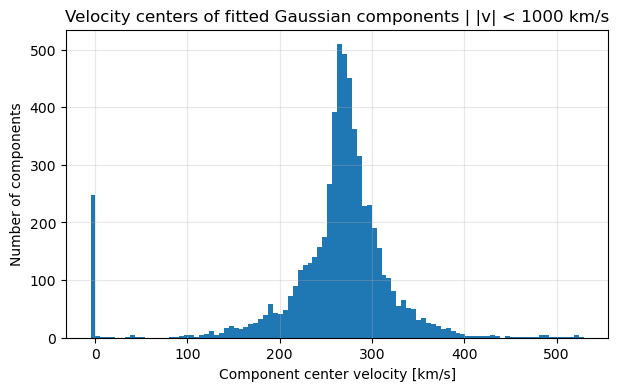

In [22]:
import matplotlib.pyplot as plt

vel = df_components["mean_kms"]

vel_filtered = vel[np.abs(vel) < 1000]

plt.figure(figsize=(7, 4))
plt.hist(vel_filtered, bins=100)
plt.xlabel("Component center velocity [km/s]")
plt.ylabel("Number of components")
plt.title("Velocity centers of fitted Gaussian components | |v| < 1000 km/s")
plt.grid(alpha=0.3)
plt.show()

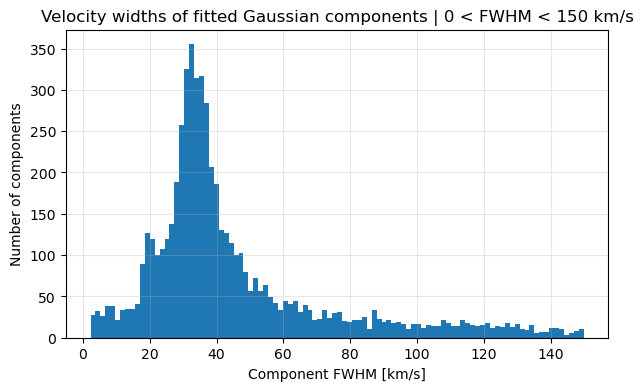

In [23]:
fwhm = df_components["fwhm_kms"]

fwhm_filtered = fwhm[(fwhm > 0) & (fwhm < 150)]

plt.figure(figsize=(7, 4))
plt.hist(fwhm_filtered, bins=100)
plt.xlabel("Component FWHM [km/s]")
plt.ylabel("Number of components")
plt.title("Velocity widths of fitted Gaussian components | 0 < FWHM < 150 km/s")
plt.grid(alpha=0.3)
plt.show()

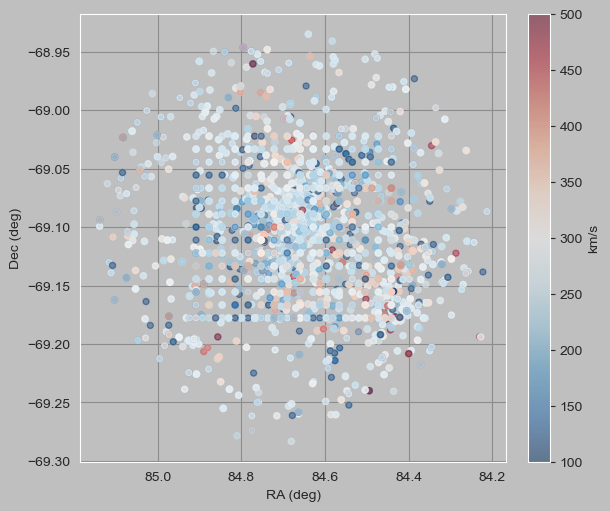

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
with sns.axes_style(
    "darkgrid",
    rc={
        "axes.facecolor": "0.75",
        "figure.facecolor": "0.75",
        "grid.color": "0.55",
    }
):
    fig, ax = plt.subplots(figsize=(6,5), constrained_layout=True)
    rad_vel = ax.scatter(df_components['ra_deg'], df_components['dec_deg'],
                             s=20.0, 
                             c=df_components['mean_kms'],#-df_components['V_mean'], 
                             cmap='RdBu_r',
                             vmin=100,
                             vmax=500,
                         alpha = 0.5
                        )
    ax.invert_xaxis()
    ax.set_xlabel("RA (deg)")
    ax.set_ylabel("Dec (deg)")
    #ax.set_title(r'H$\alpha$ - H$\beta$')
    fig.colorbar(rad_vel, ax=ax, label='km/s')
    plt.show()

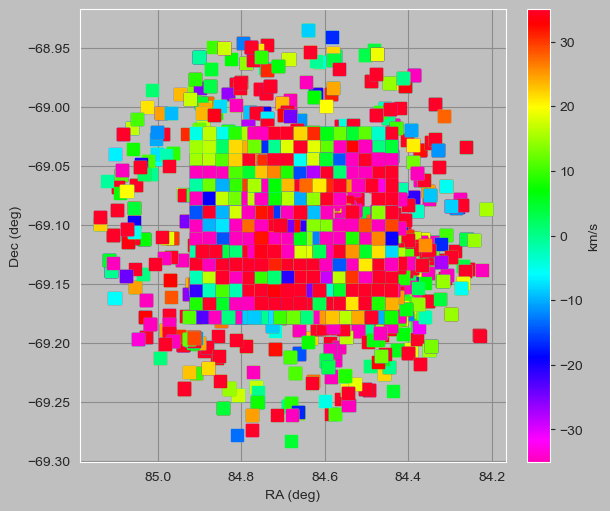

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(42)

jitter_ra = 0.000   # degrees
jitter_dec = 0.000  # degrees

ra_jittered = df_components["ra_deg"] + rng.normal(0, jitter_ra, size=len(df_components))
dec_jittered = df_components["dec_deg"] + rng.normal(0, jitter_dec, size=len(df_components))

cvals = df_components["mean_kms"] - 267.4

with sns.axes_style(
    "darkgrid",
    rc={
        "axes.facecolor": "0.75",
        "figure.facecolor": "0.75",
        "grid.color": "0.55",
    }
):
    fig, ax = plt.subplots(figsize=(6,5), constrained_layout=True)

    rad_vel = ax.scatter(
        ra_jittered,
        dec_jittered,
        s=75.0,
        c=cvals,
   #     cmap="RdBu_r",
        cmap="gist_rainbow_r",
        vmin=-35,
        vmax=+35,
        marker = 's'
    )

    ax.invert_xaxis()
    ax.set_xlabel("RA (deg)")
    ax.set_ylabel("Dec (deg)")

    fig.colorbar(rad_vel, ax=ax, label="km/s")
    plt.show()

In [26]:
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord

# Center the artificial WCS on 30 Dor / Tarantula
c0 = SkyCoord.from_name("Tarantula")

wcs = WCS(naxis=2)
wcs.wcs.ctype = ["RA---TAN", "DEC--TAN"]
wcs.wcs.cunit = ["deg", "deg"]

# Reference sky coordinate
wcs.wcs.crval = [c0.ra.deg, c0.dec.deg]

# Reference pixel
wcs.wcs.crpix = [500, 500]

# Pixel scale in degrees/pixel
# Negative RA scale gives standard astronomical orientation
wcs.wcs.cdelt = [-0.00005, 0.00005]

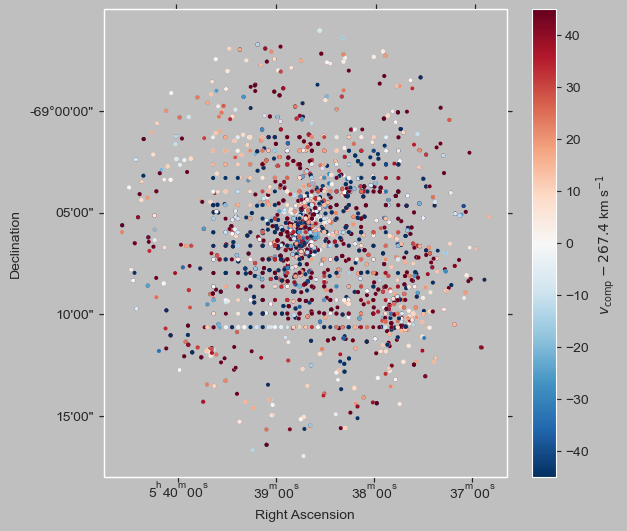

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from astropy.visualization.wcsaxes import WCSAxes

rng = np.random.default_rng(42)

jitter_ra = 0.000
jitter_dec = 0.000

ra_jittered = df_components["ra_deg"].to_numpy() + rng.normal(
    0, jitter_ra, size=len(df_components)
)

dec_jittered = df_components["dec_deg"].to_numpy() + rng.normal(
    0, jitter_dec, size=len(df_components)
)

cvals = df_components["mean_kms"].to_numpy() - 267.4

with sns.axes_style(
    "darkgrid",
    rc={
        "axes.facecolor": "0.75",
        "figure.facecolor": "0.75",
        "grid.color": "0.55",
    }
):
    fig = plt.figure(figsize=(7, 6))

    # Explicit WCSAxes construction
    ax = WCSAxes(
        fig,
        [0.12, 0.12, 0.72, 0.78],   # [left, bottom, width, height]
        wcs=wcs,
    )

    fig.add_axes(ax)

    rad_vel = ax.scatter(
        ra_jittered,
        dec_jittered,
        s=15.0,
        c=cvals,
        cmap="RdBu_r",
        vmin=-45,
        vmax=+45,
        marker=".",
        transform=ax.get_transform("world"),
    )

    ax.coords[0].set_axislabel("Right Ascension")
    ax.coords[1].set_axislabel("Declination")

    ax.coords[0].set_major_formatter("hh:mm:ss")
    ax.coords[1].set_major_formatter("dd:mm:ss")

    ax.grid(color="0.55", alpha=0.6, linestyle="--")

    fig.colorbar(
        rad_vel,
        ax=ax,
        label=r"$v_{\rm comp} - 267.4$ km s$^{-1}$",
    )

    plt.show()

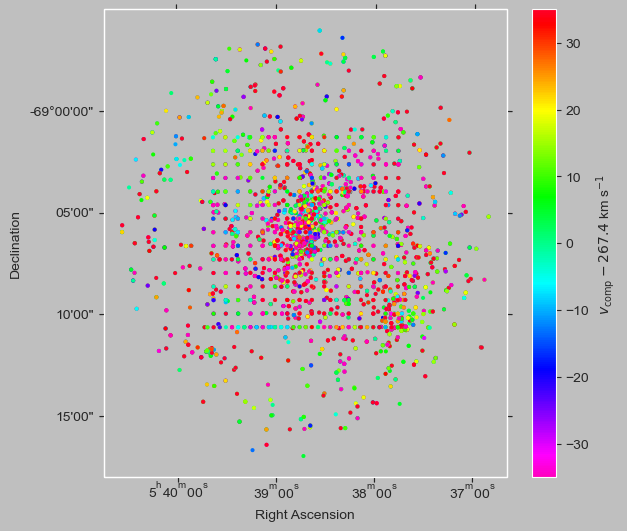

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from astropy.visualization.wcsaxes import WCSAxes

rng = np.random.default_rng(42)

jitter_ra = 0.000
jitter_dec = 0.000

ra_jittered = df_components["ra_deg"].to_numpy() + rng.normal(
    0, jitter_ra, size=len(df_components)
)

dec_jittered = df_components["dec_deg"].to_numpy() + rng.normal(
    0, jitter_dec, size=len(df_components)
)

cvals = df_components["mean_kms"].to_numpy() - 267.4

with sns.axes_style(
    "darkgrid",
    rc={
        "axes.facecolor": "0.75",
        "figure.facecolor": "0.75",
        "grid.color": "0.55",
    }
):
    fig = plt.figure(figsize=(7, 6))

    # Explicit WCSAxes construction
    ax = WCSAxes(
        fig,
        [0.12, 0.12, 0.72, 0.78],   # [left, bottom, width, height]
        wcs=wcs,
    )

    fig.add_axes(ax)

    rad_vel = ax.scatter(
        ra_jittered,
        dec_jittered,
        s=15.0,
        c=cvals,
        cmap="gist_rainbow_r",
        vmin=-35,
        vmax=+35,
        marker=".",
        transform=ax.get_transform("world"),
    )

    ax.coords[0].set_axislabel("Right Ascension")
    ax.coords[1].set_axislabel("Declination")

    ax.coords[0].set_major_formatter("hh:mm:ss")
    ax.coords[1].set_major_formatter("dd:mm:ss")

    ax.grid(color="0.55", alpha=0.6, linestyle="--")

    fig.colorbar(
        rad_vel,
        ax=ax,
        label=r"$v_{\rm comp} - 267.4$ km s$^{-1}$",
    )

    plt.show()

ValueError: 'c' argument must be a color, a sequence of colors, or a sequence of numbers, not array([array([44.54868904,  4.18367477,         nan,  7.87651729,         nan]),
       array([44.54868904,  4.18367477,         nan,  7.87651729,         nan]),
       array([44.54868904,  4.18367477,         nan,  7.87651729,         nan]),
       ...,
       array([23.28249038,  5.21038218, 13.82608022,         nan, 71.81760673]),
       array([23.28249038,  5.21038218, 13.82608022,         nan, 71.81760673]),
       array([23.28249038,  5.21038218, 13.82608022,         nan, 71.81760673])],
      dtype=object)

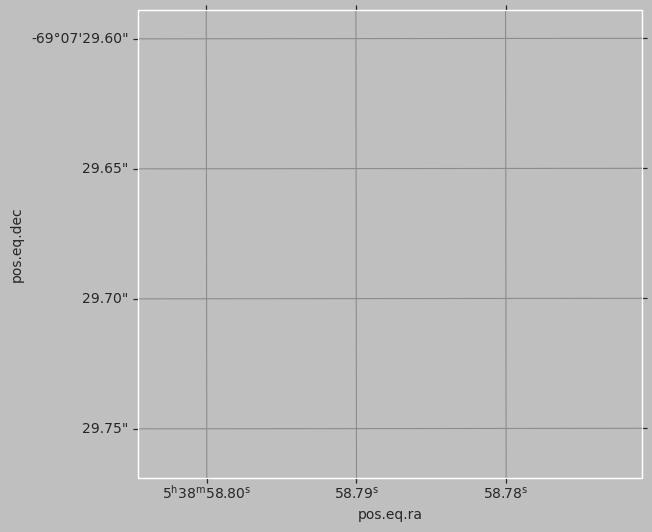

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from astropy.visualization.wcsaxes import WCSAxes

rng = np.random.default_rng(42)

jitter_ra = 0.000
jitter_dec = 0.000

ra_jittered = df_components["ra_deg"].to_numpy() + rng.normal(
    0, jitter_ra, size=len(df_components)
)

dec_jittered = df_components["dec_deg"].to_numpy() + rng.normal(
    0, jitter_dec, size=len(df_components)
)

cvals = df_components["sigma_kms"].to_numpy()

with sns.axes_style(
    "darkgrid",
    rc={
        "axes.facecolor": "0.75",
        "figure.facecolor": "0.75",
        "grid.color": "0.55",
    }
):
    fig = plt.figure(figsize=(7, 6))

    # Explicit WCSAxes construction
    ax = WCSAxes(
        fig,
        [0.12, 0.12, 0.72, 0.78],   # [left, bottom, width, height]
        wcs=wcs,
    )

    fig.add_axes(ax)

    rad_vel = ax.scatter(
        ra_jittered,
        dec_jittered,
        s=15.0,
        c=cvals,
        cmap="gist_rainbow_r",
        vmin=5,
        vmax= 45,
        marker=".",
        transform=ax.get_transform("world"),
    )

    ax.coords[0].set_axislabel("Right Ascension")
    ax.coords[1].set_axislabel("Declination")

    ax.coords[0].set_major_formatter("hh:mm:ss")
    ax.coords[1].set_major_formatter("dd:mm:ss")

    ax.grid(color="0.55", alpha=0.6, linestyle="--")

    fig.colorbar(
        rad_vel,
        ax=ax,
        label=r"$\sigma$",
    )

    plt.show()

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
with sns.axes_style(
    "darkgrid",
    rc={
        "axes.facecolor": "0.75",
        "figure.facecolor": "0.75",
        "grid.color": "0.55",
    }
):
    fig, ax = plt.subplots(figsize=(6,5), constrained_layout=True)
    rad_vel = ax.scatter(df_components['ra_deg'], df_components['dec_deg'],
                             s=15.0, 
                             c=np.log10(df_components['amp']),#-df_components['V_mean'], 
                             cmap='magma',
                           #  vmin=100,
                           #  vmax=500,
                         alpha = 1.0,
                         marker = '.'
                        )
    ax.invert_xaxis()
    ax.set_xlabel("RA (deg)")
    ax.set_ylabel("Dec (deg)")
    #ax.set_title(r'H$\alpha$ - H$\beta$')
    fig.colorbar(rad_vel, ax=ax, label='A.D.U.')
    plt.show()

In [ ]:
FILENAME_COMPONENTS_CSV = out_dir / "df_components.csv"

df_components.to_csv(FILENAME_COMPONENTS_CSV, index=False)

print("Saved:")
print(FILENAME_SUMMARY_CSV)

In [ ]:
arr0 = df_components["ra_deg"]
arr1 = df_components["dec_deg"]
arr2 = df_components["mean_kms"].to_numpy() - 267.4
arr3 = np.log10(df_components['amp'])
arr4 = np.array([x[0] for x in df_components["sigma_kms"]])

In [ ]:
arr4

In [ ]:
temp_array = np.column_stack((arr0, arr1, arr2, arr3, arr4))

In [ ]:
temp_array[0]

In [ ]:
import json

class MyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.integer):
            return int(obj)
        elif isinstance(obj, np.floating):
            return float(obj)
        elif isinstance(obj, np.ndarray):
            return obj.tolist()
        else:
            return super(MyEncoder, self).default(obj)


name = "FLAMES-30Dor-6563"
data_export_list = {
        "name": name,
        "data": temp_array,
    }

jsonfilename =  name + "-l.json"
with open(jsonfilename, "w") as f:
     json.dump(data_export_list, fp=f, indent=3, cls=MyEncoder)